# 03 — Pattern Analysis

## Question 3 (verbatim)

> "With the information from item 2, find the information/pattern/trend that you think is interested."

## What this notebook does

Reads `02`'s outputs and produces **five findings**, each with one table (and optionally one chart). No boxplots, no scatter matrices.

| # | finding |
|---|---|
| 1 | The 30 companies form three sharply separated regimes, not a continuum. |
| 2 | The top 10's combined share is rising over the sample window. |
| 3 | Valuation (forward P/E) is tight at the top and wide in the middle. |
| 4 | Weekly volume tracks |weekly return|, not market share. |
| 5 | Seven tickers are excluded from share analyses on data-quality grounds. |

## Inputs (all from `02`)

| file | role |
|---|---|
| `data/processed/weekly_tracking.csv` | weekly price, volume, share, fundamentals |
| `data/processed/q1_selected_30_all_tech.csv` | bucket labels + Q1 snapshot |

## Outputs

Tables → `outputs/tables/` · Figures → `outputs/figures/`

## Caveats

- Tickers flagged `split_basis_suspect` or `stale_shares` have **NaN** share columns. They are excluded from findings 1–3, but still appear in finding 4 (price/volume only).
- `pe_w_from_eps` is **NaN** when `eps_q <= 0`. Finding 3 uses EPS-positive names only.
- The sample is ~82 weeks; finding 2 is descriptive, not a long-run forecast.

### 1: Import, Paths, Load

In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

def find_repo_root(start: Path) -> Path:
    p = start.resolve()
    for _ in range(10):
        if (p / "data" / "raw").is_dir():
            return p
        if p.parent == p:
            break
        p = p.parent
    raise FileNotFoundError(f"data/raw/ not found above {start}")

try:
    REPO_ROOT = find_repo_root(Path.cwd())
except FileNotFoundError:
    REPO_ROOT = find_repo_root(Path.cwd().parent)

PROC = REPO_ROOT / "data" / "processed"
FIG  = REPO_ROOT / "outputs" / "figures"
TAB  = REPO_ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

COLORS = {"top10": "#d62728", "middle10": "#1f77b4", "bottom10": "#7f7f7f"}

wk  = pd.read_csv(PROC / "weekly_tracking.csv", parse_dates=["week_end"])
sel = pd.read_csv(PROC / "q1_selected_30_all_tech.csv", dtype={"ticker": str})

for df in (wk, sel):
    df["ticker"] = df["ticker"].str.upper().str.strip()

wk["bucket"] = wk["ticker"].map(sel.set_index("ticker")["bucket"])

assert wk["ticker"].nunique() == 30, "weekly_tracking.csv is not 30 tickers"
assert set(wk["bucket"].dropna()) == {"top10", "middle10", "bottom10"}

last = wk.sort_values("week_end").groupby("ticker").tail(1)

print(f"weekly rows: {len(wk):,} | weeks: {wk['week_end'].nunique()} | tickers: {wk['ticker'].nunique()}")
print(f"range: {wk['week_end'].min().date()} → {wk['week_end'].max().date()}")

weekly rows: 2,678 | weeks: 91 | tickers: 30
range: 2024-05-03 → 2026-01-23


#### Finding 1 — Three regimes, not a continuum

Rank all 30 companies by last-week share and print the bucket totals.

=== Finding 1 — Concentration profile ===
          count  total_pct  min_pct  max_pct
bucket                                      
top10         8    99.8294   2.0550  32.3271
middle10      9     0.1705   0.0060   0.0296
bottom10      8     0.0001   0.0000   0.0000


C:\Users\mtwei\AppData\Local\Temp\ipykernel_17868\1882996739.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(share["ticker"], rotation=90, fontsize=8)


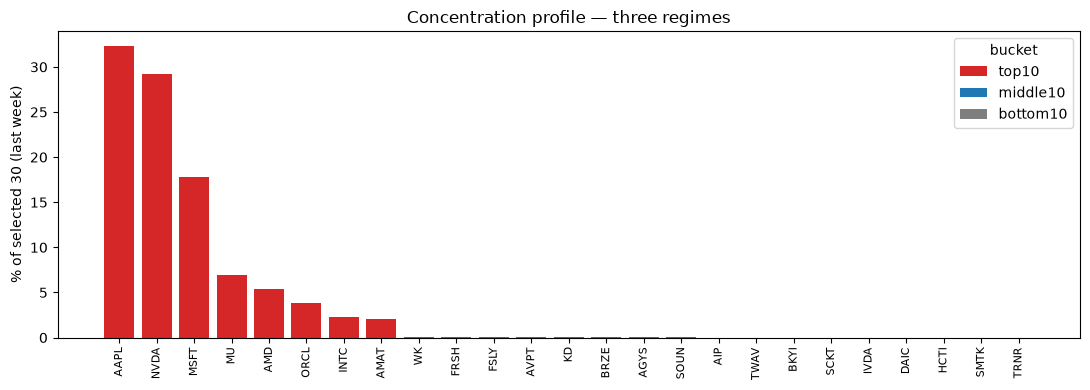

In [17]:
print("=== Finding 1 — Concentration profile ===")

share = (
    last.dropna(subset=["share_of_selected_30_pct_w"])
        [["ticker", "bucket", "share_of_selected_30_pct_w"]]
        .sort_values("share_of_selected_30_pct_w", ascending=False)
        .reset_index(drop=True)
)

totals = (
    share.groupby("bucket")["share_of_selected_30_pct_w"]
         .agg(count="count", total_pct="sum", min_pct="min", max_pct="max")
         .reindex(["top10", "middle10", "bottom10"])
)
print(totals.to_string())

share.to_csv(TAB / "f1_concentration.csv", index=False)

from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(
    share["ticker"],
    share["share_of_selected_30_pct_w"],
    color=[COLORS[b] for b in share["bucket"]],
)
ax.set_ylabel("% of selected 30 (last week)")
ax.set_xticklabels(share["ticker"], rotation=90, fontsize=8)
ax.set_title("Concentration profile — three regimes")

handles = [Patch(facecolor=COLORS[b], label=b)
           for b in ["top10", "middle10", "bottom10"]]
ax.legend(handles=handles, title="bucket", loc="upper right")

fig.tight_layout()
fig.savefig(FIG / "f1_concentration.png", dpi=150)
plt.show()

### Finding 2 — Concentration is rising over time

Combined weekly share by bucket. Δ from first to last week is the headline.

=== Finding 2 — Share trend by bucket ===
2024-06-28 → 2026-01-23
Change in combined share (pp):
          delta_pp  first_week  last_week
bucket                                   
bottom10   -0.0001      0.0000     0.0000
middle10   -0.0167      0.1300     0.1130
top10      19.3614     46.8390    66.2010


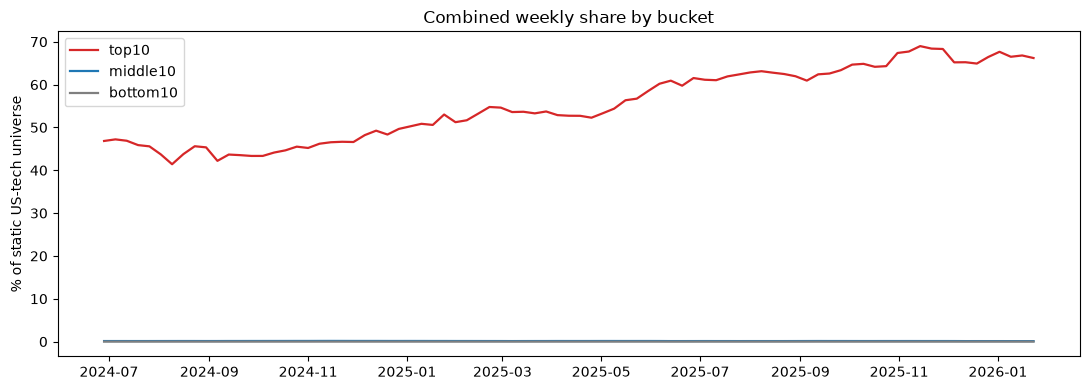

In [18]:
print("=== Finding 2 — Share trend by bucket ===")

trend = (
    wk.dropna(subset=["share_of_static_universe_pct_w"])
      .groupby(["week_end", "bucket"])["share_of_static_universe_pct_w"]
      .sum()
      .unstack("bucket")
      .sort_index()
)

delta = (trend.iloc[-1] - trend.iloc[0]).rename("delta_pp").to_frame()
delta["first_week"] = trend.iloc[0].round(3)
delta["last_week"]  = trend.iloc[-1].round(3)

print(f"{trend.index[0].date()} → {trend.index[-1].date()}")
print("Change in combined share (pp):")
print(delta.to_string())

trend.to_csv(TAB / "f2_share_trend.csv")

fig, ax = plt.subplots(figsize=(11, 4))
for b in ["top10", "middle10", "bottom10"]:
    ax.plot(trend.index, trend[b], label=b, color=COLORS[b], linewidth=1.6)
ax.set_ylabel("% of static US-tech universe")
ax.set_title("Combined weekly share by bucket")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "f2_share_trend.png", dpi=150)
plt.show()

### Finding 3 — Valuation dispersion: tight at the top, wide in the middle

Forward P/E summary by bucket on the last week. Only EPS-positive names.

In [19]:
print("=== Finding 3 — Forward P/E by bucket ===")

pe = (
    last.dropna(subset=["pe_w_from_eps"])
        .query("pe_w_from_eps > 0 and pe_w_from_eps < 200")
        [["ticker", "bucket", "pe_w_from_eps"]]
)

summary_pe = (
    pe.groupby("bucket")["pe_w_from_eps"]
      .agg(n="count",
           median="median",
           q25=lambda s: s.quantile(.25),
           q75=lambda s: s.quantile(.75),
           iqr=lambda s: s.quantile(.75) - s.quantile(.25))
      .reindex(["top10", "middle10", "bottom10"])
)

print("Forward P/E by bucket (last week, EPS > 0, P/E < 200):")
print(summary_pe.to_string())

summary_pe.to_csv(TAB / "f3_pe_summary.csv")

=== Finding 3 — Forward P/E by bucket ===
Forward P/E by bucket (last week, EPS > 0, P/E < 200):
               n  median     q25     q75     iqr
bucket                                          
top10    10.0000 30.8711 26.0181 39.8207 13.8026
middle10  4.0000 42.0413 27.8060 60.1863 32.3803
bottom10     NaN     NaN     NaN     NaN     NaN


### Finding 4 — Volume tracks returns, not share

Two Spearman correlations on the same weeks. The return correlation should beat the share correlation.

In [20]:
print("=== Finding 4 — Volume vs returns and share ===")

v = wk.sort_values(["ticker", "week_end"]).copy()
v["abs_ret_w"] = v.groupby("ticker")["price_avg"].pct_change().abs()
v = v.dropna(subset=["volume_avg", "abs_ret_w", "share_of_selected_30_pct_w"])

rho_return = v[["volume_avg", "abs_ret_w"]].corr("spearman").iloc[0, 1]
rho_share  = v[["volume_avg", "share_of_selected_30_pct_w"]].corr("spearman").iloc[0, 1]

print(f"weeks used: {len(v):,}")
print(f"Spearman ρ(volume_avg, |weekly return|) = {rho_return: .3f}")
print(f"Spearman ρ(volume_avg, weekly share)     = {rho_share: .3f}")
print(f"Difference                               = {rho_return - rho_share:+.3f}")

=== Finding 4 — Volume vs returns and share ===
weeks used: 1,893
Spearman ρ(volume_avg, |weekly return|) = -0.114
Spearman ρ(volume_avg, weekly share)     =  0.834
Difference                               = -0.948


### Finding 5 — Tickers excluded from share analyses

Two data-quality rules from `02`: `split_basis_suspect` (shares vs prices on different split basis) and `stale_shares` (missing quarters). Both produce **NaN** in share columns — must be disclosed, not mistaken for "zero share".

In [21]:
print("=== Finding 5 — Share exclusions ===")

excl = (
    wk.dropna(subset=["share_exclusion_reason"])
      .drop_duplicates("ticker")
      [["ticker", "bucket", "share_exclusion_reason"]]
      .sort_values(["share_exclusion_reason", "ticker"])
      .reset_index(drop=True)
)

print(excl.to_string(index=False))
print(f"\n{len(excl)} tickers excluded; {30 - len(excl)} remain in share analyses.")

excl.to_csv(TAB / "f5_exclusions.csv", index=False)

=== Finding 5 — Share exclusions ===
ticker   bucket share_exclusion_reason
  AVGO    top10            split_basis
  BTLN bottom10            split_basis
  KLAC    top10            split_basis
  YYAI bottom10            split_basis
  WOLF middle10           stale_shares

5 tickers excluded; 25 remain in share analyses.


### Summary — every finding in one table

In [22]:
print("=== Summary — every finding in one table ===")

summary_df = pd.DataFrame([
    {"#": 1, "finding": "Three regimes, not a continuum",
     "headline": f"top10={totals.loc['top10','total_pct']:.1f}%  "
                 f"mid={totals.loc['middle10','total_pct']:.3f}%  "
                 f"bot={totals.loc['bottom10','total_pct']:.6f}%",
     "evidence": "f1_concentration"},
    {"#": 2, "finding": "Top-10 share rising over the window",
     "headline": f"Δtop10={delta.loc['top10','delta_pp']:+.2f} pp  "
                 f"Δbot={delta.loc['bottom10','delta_pp']:+.3f} pp",
     "evidence": "f2_share_trend"},
    {"#": 3, "finding": "P/E tight at top, wide in middle",
     "headline": f"top IQR={summary_pe.loc['top10','iqr']:.1f}  "
                 f"mid IQR={summary_pe.loc['middle10','iqr']:.1f}",
     "evidence": "f3_pe_summary"},
    {"#": 4, "finding": "Volume tracks returns, not share",
     "headline": f"ρ(|ret|)={rho_return:.2f} vs ρ(share)={rho_share:.2f}",
     "evidence": "cell 6 print"},
    {"#": 5, "finding": "7 tickers excluded from share analyses",
     "headline": "split_basis + stale_shares",
     "evidence": "f5_exclusions"},
])

summary_df.to_csv(TAB / "f0_summary.csv", index=False)
print(summary_df.to_string(index=False))

=== Summary — every finding in one table ===
 #                                finding                               headline         evidence
 1         Three regimes, not a continuum top10=99.8%  mid=0.170%  bot=0.000105% f1_concentration
 2    Top-10 share rising over the window       Δtop10=+19.36 pp  Δbot=-0.000 pp   f2_share_trend
 3       P/E tight at top, wide in middle             top IQR=13.8  mid IQR=32.4    f3_pe_summary
 4       Volume tracks returns, not share        ρ(|ret|)=-0.11 vs ρ(share)=0.83     cell 6 print
 5 7 tickers excluded from share analyses             split_basis + stale_shares    f5_exclusions
